<a href="https://colab.research.google.com/github/zxaredj/data-analytics-project/blob/main/side_projects.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Employee Attrition Analytics — Executive Summary

## Project Overview

This project analyzes employee attrition patterns using demographic, educational, compensation-tier, location, and employment-related data. The objective is to identify workforce characteristics associated with employee departures and generate actionable insights to support employee retention and workforce planning.

## Dataset Overview

- Total employees analyzed: 2,764
- Employees who stayed: 1,676
- Employees who left: 1,088
- Overall attrition rate: 39.36%

## Key Findings

1. **Payment Tier:** Tier 2 employees recorded the highest attrition rate at 60.18%, compared with 35.32% for Tier 1 and 33.81% for Tier 3. Payment tier also demonstrated the strongest categorical association with attrition among the variables tested (Cramér's V = 0.22).

2. **Location:** Pune recorded the highest attrition rate at 50.94%, followed by Bangalore at 35.01% and New Delhi at 34.09%.

3. **Gender:** Female employees had an observed attrition rate of 49.72%, compared with 31.00% for male employees. This difference warrants further investigation into workforce conditions and employee experience.

4. **Education:** Employees with Master's degrees had the highest attrition rate at 48.51%, followed by Bachelor's degree holders at 37.49% and PhD holders at 25.64%.

5. **Age:** Employees who left had a median age of 29, compared with 30 among employees who stayed. The point-biserial correlation was weak and negative (r = -0.11).

6. **Joining Year:** Joining year demonstrated a weak positive association with attrition (r = 0.15), suggesting that employees with more recent joining years tended to have higher attrition.

7. **Bench Status:** Employees who were benched had an attrition rate of 44.04%, compared with 38.66% among employees who were not benched. However, the chi-square result was not statistically significant at the 0.05 level (p = 0.06).

8. **Experience:** Experience in the current domain did not demonstrate a statistically significant relationship with attrition in the tests performed.

## Statistical Methods

The analysis used:
- Descriptive statistics and categorical attrition-rate comparisons
- Chi-square tests of independence
- Cramér's V for categorical association strength
- Mann-Whitney U tests for numerical group comparisons
- Point-biserial correlation for numerical variables against the binary attrition outcome
- Benjamini-Hochberg false discovery rate adjustment for multiple statistical tests

## Business Recommendations

- Review compensation and career progression structures, particularly for Payment Tier 2 employees.
- Investigate workforce conditions and employee experience in Pune.
- Evaluate career development, promotion accessibility, and employee experience across workforce groups.
- Assess role alignment and advancement opportunities for employees with advanced educational qualifications.
- Monitor employee bench utilization and assignment duration.
- Develop a recurring attrition monitoring dashboard to track workforce trends and support management decisions.

## Conclusion

The analysis identified several employee characteristics associated with attrition, with payment tier, location, gender, and education showing notable differences in observed attrition rates.

Although several statistical relationships were significant, their effect sizes were generally small. The findings should therefore be treated as indicators for further investigation rather than evidence of direct causation.

The project demonstrates how data cleaning, exploratory data analysis, statistical testing, and business interpretation can be combined to transform raw employee records into actionable workforce insights.

In [2]:
#importing file from gdrive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/project_dataset/Employee_Analytics/Raw Data/Employee.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  4653 non-null   object
 1   JoiningYear                4653 non-null   int64 
 2   City                       4653 non-null   object
 3   PaymentTier                4653 non-null   int64 
 4   Age                        4653 non-null   int64 
 5   Gender                     4653 non-null   object
 6   EverBenched                4653 non-null   object
 7   ExperienceInCurrentDomain  4653 non-null   int64 
 8   LeaveOrNot                 4653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 327.3+ KB


In [5]:
df.head()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


In [6]:
#import python libraries

#for data manipulation
import pandas as pd
import numpy as np

#for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

#for data viz
import matplotlib.pyplot as plt
import seaborn as sns

#for stats
from scipy import stats

#for file mgmt
import os
from pathlib import Path

#for data validation
from IPython.display import display

#for warning mgmt
import warnings
warnings.filterwarnings('ignore')

#for viz setting
sns.set_theme(style='whitegrid')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

#for pandas display setting
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.2f}'.format)

print("Libraries successfully imported!")

Libraries successfully imported!


In [7]:
#proj directory config
PROJECT_PATH = Path(
    "/content/drive/MyDrive/project_dataset/Employee_Analytics"
)

RAW_PATH = PROJECT_PATH / 'Raw Data'
CLEAN_PATH = PROJECT_PATH / 'Cleaned Data'
REPORT_PATH = PROJECT_PATH / 'Reports'
VIZ_PATH = PROJECT_PATH / 'Visualization'

#create output directories if they dont exist
for folder in [CLEAN_PATH, REPORT_PATH, VIZ_PATH]:
  folder.mkdir(parents=True, exist_ok=True)

#display directory configg
print("Project directories configured.")

print("Raw Data:", RAW_PATH)

Project directories configured.
Raw Data: /content/drive/MyDrive/project_dataset/Employee_Analytics/Raw Data


In [8]:
#locating my dataset
csv_files = list(RAW_PATH.glob('*.csv'))

print("CSV files found:", len(csv_files))

for file in csv_files:
  print(file.name)

CSV files found: 1
Employee.csv


In [9]:
#load the dataset
FILE_PATH = RAW_PATH / 'Employee.csv'

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {FILE_PATH}"
    )

employee_raw = pd.read_csv(FILE_PATH)

#make a copy/backup
employee = employee_raw.copy()

print("Dataset successfully loaded!")
print("Rows:", employee_raw.shape[0])
print("Columns:", employee_raw.shape[1])

Dataset successfully loaded!
Rows: 4653
Columns: 9


In [10]:
#eda

# Ensure the 'employee' variable is defined in active memory
if 'employee' not in globals() and 'employee_raw' in globals():
    employee = employee_raw.copy()

print("Dataset Overview")
print("=" *50)

print("Dataset Shape:", employee.shape)

print("\nColumn Names:")
print(employee.columns.tolist())

print("\nData Types:")
print(employee.dtypes)

print("\nFirst 10 Records:")
display(employee.head(10))

print("\nLast 10 Records:")
display(employee.tail(10))

print("\nRandom 10 Records:")
print(employee.sample(min(10, len(employee)), random_state=42))

print("\nMissing Values:")
print(employee.isnull().sum())

print("\nSummary Statistics:")
print(employee.describe())

Dataset Overview
Dataset Shape: (4653, 9)

Column Names:
['Education', 'JoiningYear', 'City', 'PaymentTier', 'Age', 'Gender', 'EverBenched', 'ExperienceInCurrentDomain', 'LeaveOrNot']

Data Types:
Education                    object
JoiningYear                   int64
City                         object
PaymentTier                   int64
Age                           int64
Gender                       object
EverBenched                  object
ExperienceInCurrentDomain     int64
LeaveOrNot                    int64
dtype: object

First 10 Records:


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1
5,Bachelors,2016,Bangalore,3,22,Male,No,0,0
6,Bachelors,2015,New Delhi,3,38,Male,No,0,0
7,Bachelors,2016,Bangalore,3,34,Female,No,2,1
8,Bachelors,2016,Pune,3,23,Male,No,1,0
9,Masters,2017,New Delhi,2,37,Male,No,2,0



Last 10 Records:


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
4643,Bachelors,2013,Bangalore,3,31,Female,No,5,0
4644,Bachelors,2015,Pune,3,32,Female,Yes,1,1
4645,Masters,2017,Pune,2,31,Female,No,2,0
4646,Bachelors,2013,Bangalore,3,25,Female,No,3,0
4647,Bachelors,2016,Pune,3,30,Male,No,2,0
4648,Bachelors,2013,Bangalore,3,26,Female,No,4,0
4649,Masters,2013,Pune,2,37,Male,No,2,1
4650,Masters,2018,New Delhi,3,27,Male,No,5,1
4651,Bachelors,2012,Bangalore,3,30,Male,Yes,2,0
4652,Bachelors,2015,Bangalore,3,33,Male,Yes,4,0



Random 10 Records:
      Education  JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
297   Bachelors         2016  Bangalore            3   24  Female          No   
2705  Bachelors         2013  Bangalore            3   26  Female          No   
501   Bachelors         2017  New Delhi            2   25  Female          No   
1272    Masters         2015       Pune            2   28  Female          No   
3956  Bachelors         2012  Bangalore            3   33    Male          No   
322     Masters         2012  New Delhi            3   24  Female          No   
1417  Bachelors         2016       Pune            3   27  Female          No   
1034  Bachelors         2015       Pune            2   25  Female         Yes   
1161  Bachelors         2015  New Delhi            3   28    Male          No   
1094  Bachelors         2015       Pune            2   27  Female          No   

      ExperienceInCurrentDomain  LeaveOrNot  
297                           2           

In [11]:
#data profiling

def generate_data_profile(df):

  profile = pd.DataFrame({
      'Column Name': df.columns,
      'Data Type': df.dtypes.astype(str).values,
      'Non-Null Count': df.notna().sum().values,
      'Missing Count': df.isna().sum().values,
      'Missing_Percentage': (
          df.isna().mean().values * 100
      )
  })

  profile['Missing_Percentage'] = profile['Missing_Percentage'].round(2)

  return profile.sort_values(
      'Missing_Percentage', ascending=False
  ).reset_index(drop=True)

data_profile = generate_data_profile(employee)

display(data_profile)

data_profile.to_csv(
    REPORT_PATH / 'employee_data_profile.csv', index=False
)

,Column Name,Data Type,Non-Null Count,Missing Count,Missing_Percentage
0,Education,object,4653,0,0.00
1,JoiningYear,int64,4653,0,0.00
2,City,object,4653,0,0.00
3,PaymentTier,int64,4653,0,0.00
4,Age,int64,4653,0,0.00
5,Gender,object,4653,0,0.00
6,EverBenched,object,4653,0,0.00
7,ExperienceInCurrentDomain,int64,4653,0,0.00
8,LeaveOrNot,int64,4653,0,0.00


In [12]:
#missing values

missing_summary = pd.DataFrame({
    'Column Name': employee.columns,
    'Missing Count': employee.isna().sum().values,
    'Missing Percentage': (
        employee.isna().mean().values * 100
    )
})

missing_summary = missing_summary.sort_values(
    'Missing Percentage', ascending=False
).reset_index(drop=True)

display(missing_summary)

#missing viz
missing_data = missing_summary[
    missing_summary['Missing Percentage'] > 0
]

if not missing_data.empty:
  plt.figure(figsize=(12, 6))
  sns.barplot(
      x='index',
      y='Missing Percentage'
  )

  plt.title('Missing Values by Column')
  plt.xlabel('Columns')
  plt.ylabel('Missing Percentage (%)')
  plt.xticks(rotation=45, ha='right')
  plt.tight_layout()
  plt.show()

else:
  print("No missing data found.")

,Column Name,Missing Count,Missing Percentage
0,Education,0,0.00
1,JoiningYear,0,0.00
2,City,0,0.00
3,PaymentTier,0,0.00
4,Age,0,0.00
5,Gender,0,0.00
6,EverBenched,0,0.00
7,ExperienceInCurrentDomain,0,0.00
8,LeaveOrNot,0,0.00


No missing data found.


In [13]:
#finding duplicate record

exact_duplicates = employee.duplicated().sum()

print("Exact duplicated records:", exact_duplicates)

duplicate_records = employee[employee.duplicated()]

display(duplicate_records.head(20))

Exact duplicated records: 1889


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
111,Bachelors,2017,Pune,2,27,Female,No,5,1
130,Bachelors,2017,Bangalore,3,26,Female,No,4,0
138,Bachelors,2017,New Delhi,3,28,Male,No,2,0
160,Bachelors,2014,Bangalore,3,28,Female,No,3,0
167,Bachelors,2014,Bangalore,3,25,Male,No,3,0
174,Bachelors,2013,Bangalore,3,26,Male,No,4,0
175,Bachelors,2016,Bangalore,3,26,Male,No,4,0
176,Bachelors,2012,Bangalore,3,25,Male,No,3,0
177,Bachelors,2015,Bangalore,3,25,Male,No,3,0
181,Bachelors,2015,Pune,3,27,Male,No,5,0


In [14]:
#stats summary

numerical_summary = employee.describe(
    include=[np.number]
).T

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max
JoiningYear,"4,653.00","2,015.06",1.86,"2,012.00","2,013.00","2,015.00","2,017.00","2,018.00"
PaymentTier,"4,653.00",2.70,0.56,1.00,3.00,3.00,3.00,3.00
Age,"4,653.00",29.39,4.83,22.00,26.00,28.00,32.00,41.00
ExperienceInCurrentDomain,"4,653.00",2.91,1.56,0.00,2.00,3.00,4.00,7.00
LeaveOrNot,"4,653.00",0.34,0.48,0.00,0.00,0.00,1.00,1.00


In [15]:
#categorical cols

categorical_columns = employee.select_dtypes(
    include=['object', 'category', 'string']
).columns

for column in categorical_columns:

  print(f"\nColumn: {column}")
  print("="*50)

  display(
      employee[column].value_counts(dropna=False).head(15)
  )


Column: Education


,count
Education,
Bachelors,3601
Masters,873
PHD,179



Column: City


,count
City,
Bangalore,2228
Pune,1268
New Delhi,1157



Column: Gender


,count
Gender,
Male,2778
Female,1875



Column: EverBenched


,count
EverBenched,
No,4175
Yes,478


In [16]:
#standardized column names
import re

def clean_column_names(df):

  df = df.copy()

  df.columns = [
      re.sub(
          r'[^a-zA-Z0-9+]', '_', str(column).strip().lower()
      ).strip('_')
      for column in df.columns
  ]

  return df

employee = clean_column_names(employee)

print("Standardized column names:")
print(employee.columns.tolist())

Standardized column names:
['education', 'joiningyear', 'city', 'paymenttier', 'age', 'gender', 'everbenched', 'experienceincurrentdomain', 'leaveornot']


In [17]:
#standardized text values

employee = employee.copy()

text_columns = employee.select_dtypes(
    include=['object', 'string']
).columns

for column in text_columns:
  employee[column] = (employee[column].astype('string').str.strip().replace('', pd.NA))

print("Text standardization completed")

Text standardization completed


In [18]:
#remove confirmed exact duplicate

duplicates_before = employee.duplicated().sum()

employee = employee.drop_duplicates()

duplicates_after = employee.duplicated().sum()

print("Duplicates before:", duplicates_before)
print("Duplicates after:", duplicates_after)
print("Rows remaining:", len(employee))

Duplicates before: 1889
Duplicates after: 0
Rows remaining: 2764


In [19]:
#data type inspection

display(
    pd.DataFrame({
        'Column': employee.columns,
        'Data Type': employee.dtypes.astype(str).values,
        'Unique Values': employee.nunique().values
    })
)

,Column,Data Type,Unique Values
0,education,string,3
1,joiningyear,int64,7
2,city,string,3
3,paymenttier,int64,3
4,age,int64,20
5,gender,string,2
6,everbenched,string,2
7,experienceincurrentdomain,int64,8
8,leaveornot,int64,2


In [20]:
#missing value treatment for handling missing values

missing_analysis = pd.DataFrame({
    'Column Name': employee.columns,
    'Missing Count': employee.isna().sum().values,
    'Missing Percentage': (
        employee.isna().mean().values * 100
    ),
    'Data Type': employee.dtypes.astype(str).values,
    'Unique Values': employee.nunique().values
})

missing_analysis = missing_analysis[
    missing_analysis['Missing Percentage'] > 0
].sort_values(
    'Missing Percentage', ascending=False
).reset_index(drop=True)

display(missing_analysis)


,Column Name,Missing Count,Missing Percentage,Data Type,Unique Values


In [21]:
#outlier detection analysis

outlier_columns = [
    'age',
    'experienceincurrentdomain'
]

outlier_results = []

for column in outlier_columns:
  q1 = employee[column].quantile(0.25)
  q3 = employee[column].quantile(0.75)
  iqr = q3 - q1

  lower_bound = q1 - (1.5 * iqr)
  upper_bound = q3 + (1.5 * iqr)

  outlier_mask = (
      (employee[column] < lower_bound) |
      (employee[column] > upper_bound)
  )

  outlier_count = outlier_mask.sum()
  outlier_percentage = (outlier_count / len(employee)) * 100

  outlier_results.append({
      'Column': column,
      'Q1': q1,
      'Q3': q3,
      'IQR': iqr,
      'Lower Bound': lower_bound,
      'Upper Bound': upper_bound,
      'Outlier Count': outlier_count,
      'Outlier Percentage': outlier_percentage
  })

outlier_analysis = pd.DataFrame(outlier_results)

display(outlier_analysis.round(2))

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,27.00,35.00,8.00,15.00,47.00,0,0.00
1,experienceincurrentdomain,1.00,4.00,3.00,-3.50,8.50,0,0.00


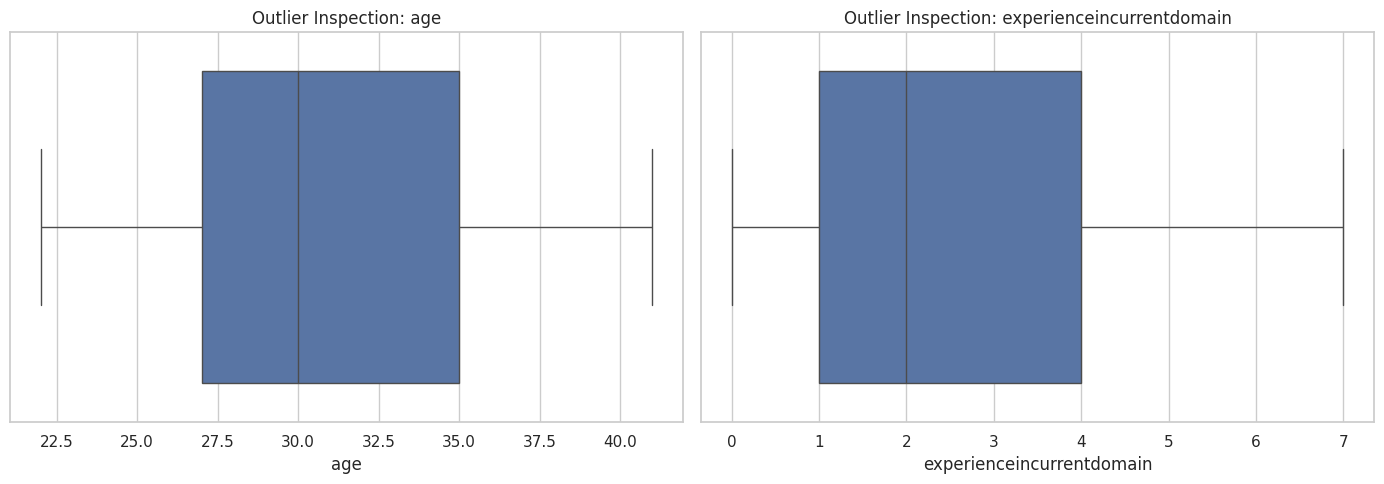

In [22]:
#outlier viz

fig, axes = plt.subplots(
    1,2,
    figsize=(14, 5)
)

for ax, column in zip(axes, outlier_columns):
  sns.boxplot(
      data=employee,
      x=column,
      ax=ax
  )

  ax.set_title(f'Outlier Inspection: {column}')

plt.tight_layout()
plt.show()

In [23]:
#biz rule validation

validation_report = {}

#education validation
valid_education = [
    'Bachelors',
    'Masters',
    'PHD'
]

validation_report['Invalid education'] = (
    ~employee['education'].isin(valid_education)
).sum()

#payment tier validation
validation_report['Invalid payment tier'] = (
    ~employee['paymenttier'].isin([1, 2, 3])
).sum()

#gender validation
validation_report['Invalid gender'] = (
    ~employee['gender'].isin(['Male', 'Female'])
).sum()

#joining year validation
validation_report['Invalid joining year'] = (
    (employee['joiningyear'] < 2010) | (employee['joiningyear'] > 2020)
).sum()

#city validation
validation_report['Invalid city'] = (
    ~employee['city'].isin(['Bangalore', 'New Delhi', 'Pune'])
).sum()

#everbenched validation
validation_report['Invalid everbenched'] = (
    ~employee['everbenched'].isin(['Yes', 'No'])
).sum()

#leaveornot validation
validation_report['Invalid leaveornot'] = (
    ~employee['leaveornot'].isin([0,1])
).sum()

#experienceincurrentdomain validation
validation_report['Invalid experienceincurrentdomain'] = (
    (employee['experienceincurrentdomain'] < 0) |
    (employee['experienceincurrentdomain'] > 7)
).sum()

#age validation
validation_report['Invalid age'] = (
    (employee['age'] < 18) | (employee['age'] > 60)
).sum()

validation_df = pd.DataFrame(
    validation_report.items(),
    columns=['Validation Rule', 'Invalid Record Count']
)

display(validation_df)

,Validation Rule,Invalid Record Count
0,Invalid education,0
1,Invalid payment tier,0
2,Invalid gender,0
3,Invalid joining year,0
4,Invalid city,0
5,Invalid everbenched,0
6,Invalid leaveornot,0
7,Invalid experienceincurrentdomain,0
8,Invalid age,0


In [24]:
#attrition stats

employee['AttritionStatus'] = employee['leaveornot'].map({
    0: 'Stayed',
    1: 'Left'
})

display(
    employee[
        ['leaveornot', 'AttritionStatus']
    ].head(10)
)

,leaveornot,AttritionStatus
0,0,Stayed
1,1,Left
2,0,Stayed
3,1,Left
4,1,Left
5,0,Stayed
6,0,Stayed
7,1,Left
8,0,Stayed
9,0,Stayed


In [25]:
#exp level

employee['ExperienceLevel'] = pd.cut(
    employee['experienceincurrentdomain'],
    bins=[-1, 2, 5, np.inf],
    labels=['Junior', 'Intermediate', 'Senior']
)

display(
    employee[
        ['experienceincurrentdomain', 'ExperienceLevel']
    ].head(10)
)

,experienceincurrentdomain,ExperienceLevel
0,0,Junior
1,3,Intermediate
2,2,Junior
3,5,Intermediate
4,2,Junior
5,0,Junior
6,0,Junior
7,2,Junior
8,1,Junior
9,2,Junior


In [26]:
#joining cohort

employee['JoiningCohort'] = employee[
    'joiningyear'
].astype('Int64')

display(
    employee[
        ['joiningyear', 'JoiningCohort']
    ].head(10)
)

,joiningyear,JoiningCohort
0,2017,2017
1,2013,2013
2,2014,2014
3,2016,2016
4,2017,2017
5,2016,2016
6,2015,2015
7,2016,2016
8,2016,2016
9,2017,2017


In [27]:
#overall attrition analysis

attrition_summary = (
    employee['AttritionStatus']
    .value_counts()
    .reset_index()
)

attrition_summary.columns = [
    'AttritionStatus',
    'Employee_Count'
]

attrition_summary['Percentage'] = (
    attrition_summary['Employee_Count'] / len(employee) * 100
)

display(attrition_summary.round(2))

,AttritionStatus,Employee_Count,Percentage
0,Stayed,1676,60.64
1,Left,1088,39.36


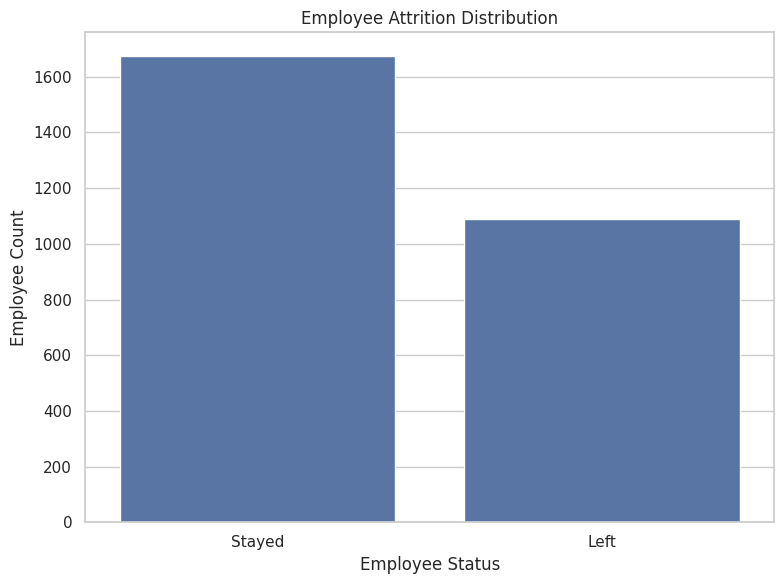

In [28]:
#attrition viz

plt.figure(figsize=(8, 6))

sns.countplot(
    data=employee,
    x='AttritionStatus',
    order=['Stayed', 'Left']
)

plt.title('Employee Attrition Distribution')
plt.xlabel('Employee Status')
plt.ylabel('Employee Count')

plt.tight_layout()
plt.show()

In [29]:
#attrition by education

education_attrition = (
    employee.groupby('education', observed=True).agg(
        Total_Employees = ('leaveornot', 'size'),
        Employees_Left = ('leaveornot', 'sum')
    )
)

education_attrition['Attrition_Rate'] = (
    education_attrition['Employees_Left'] / education_attrition['Total_Employees'] * 100
)

education_attrition = education_attrition.sort_values(
    'Attrition_Rate', ascending=False
)

display(education_attrition.round(2))


,Total_Employees,Employees_Left,Attrition_Rate
education,,,
Masters,637,309,48.51
Bachelors,1971,739,37.49
PHD,156,40,25.64


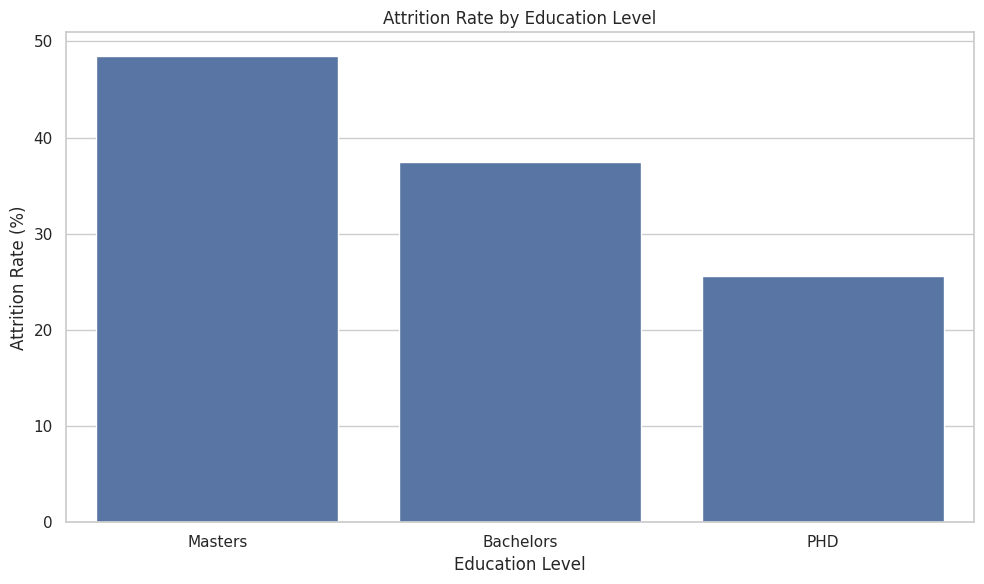

In [30]:
#educ attrition viz

plt.figure(figsize=(10, 6))

sns.barplot(
    x='education',
    y='Attrition_Rate',
    data=education_attrition.reset_index()
)

plt.title('Attrition Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Attrition Rate (%)')

plt.tight_layout()
plt.show()

In [31]:
#attrition by city

city_attrition = (
    employee.groupby('city', observed=True).agg(
        Total_Employees = ('leaveornot', 'size'),
        Employees_Left = ('leaveornot', 'sum')
    )
)

city_attrition['Attrition_Rate'] = (
    city_attrition['Employees_Left'] / city_attrition['Total_Employees'] * 100
)

city_attrition = city_attrition.sort_values(
    'Attrition_Rate', ascending=False
)

display(city_attrition.round(2))

,Total_Employees,Employees_Left,Attrition_Rate
city,,,
Pune,801,408,50.94
Bangalore,1171,410,35.01
New Delhi,792,270,34.09


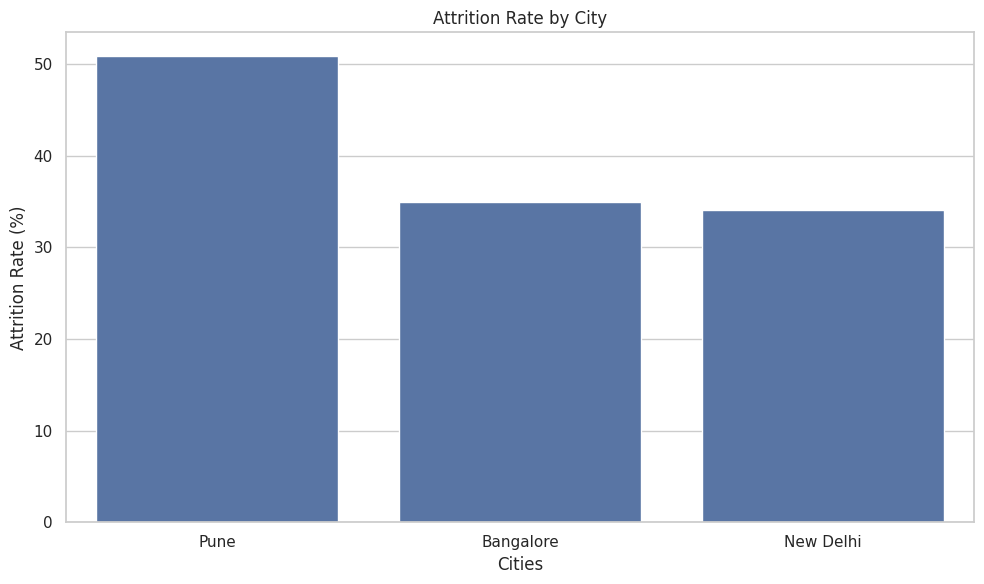

In [32]:
#attrition by city viz

plt.figure(figsize=(10, 6))

sns.barplot(
    x='city',
    y='Attrition_Rate',
    data=city_attrition.reset_index()
)

plt.title('Attrition Rate by City')
plt.xlabel('Cities')
plt.ylabel('Attrition Rate (%)')

plt.tight_layout()
plt.show()

In [33]:
#attrition by payment tier

payment_attrition = (
    employee.groupby('paymenttier', observed=True).agg(
        Total_Employees = ('leaveornot', 'size'),
        Employees_Left = ('leaveornot', 'sum')
    )
)

payment_attrition['Attrition_Rate'] = (
    payment_attrition['Employees_Left'] / payment_attrition['Total_Employees'] * 100
)

payment_attrition = payment_attrition.sort_values(
    'Attrition_Rate', ascending=False
)

display(payment_attrition.round(2))

,Total_Employees,Employees_Left,Attrition_Rate
paymenttier,,,
2,570,343,60.18
1,218,77,35.32
3,1976,668,33.81


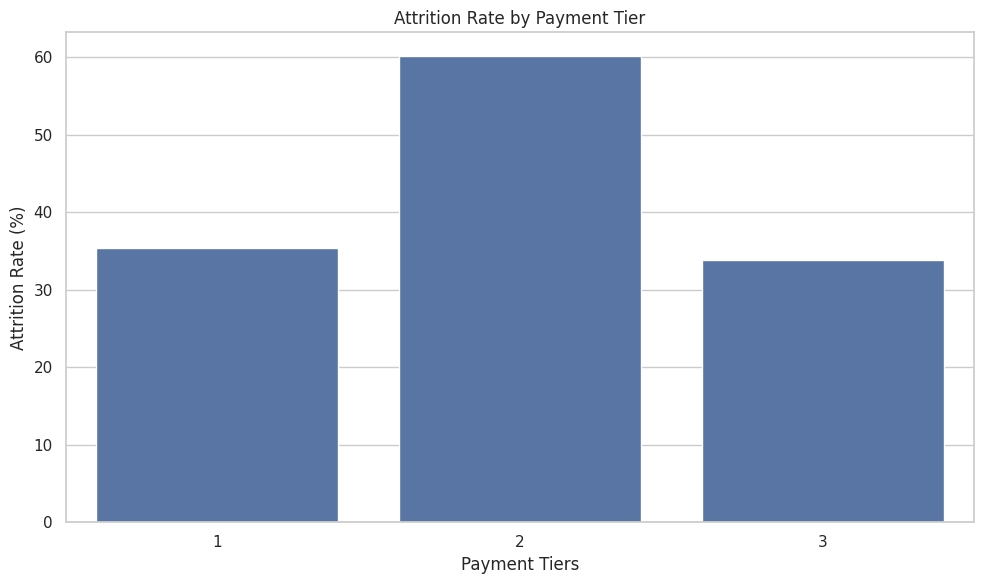

In [34]:
#attrition by payment tier viz

plt.figure(figsize=(10, 6))

sns.barplot(
    x='paymenttier',
    y='Attrition_Rate',
    data=payment_attrition.reset_index()
)

plt.title('Attrition Rate by Payment Tier')
plt.xlabel('Payment Tiers')
plt.ylabel('Attrition Rate (%)')

plt.tight_layout()
plt.show()

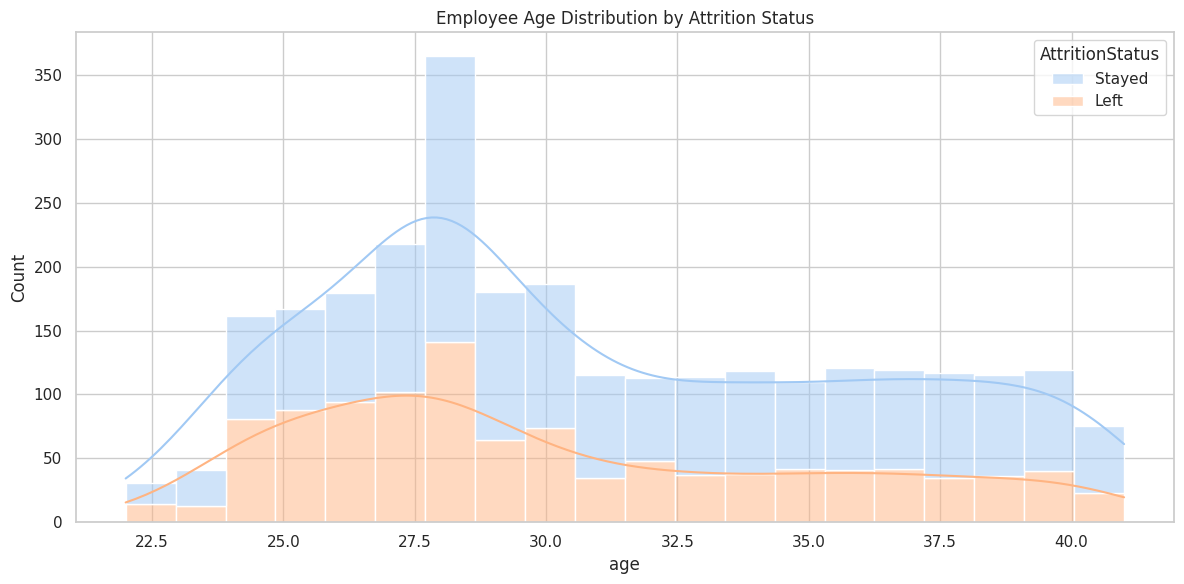

,count,min,max,mean,median
AttritionStatus,,,,,
Left,1088,22,41,30.22,29.00
Stayed,1676,22,41,31.43,30.00


In [35]:
#attrition by age

sns.histplot(
    data=employee,
    x='age',
    hue='AttritionStatus',
    multiple='stack',
    palette='pastel',
    bins = 20,
    kde=True
)

plt.title('Employee Age Distribution by Attrition Status')
plt.xlabel('age')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

age_attrition = (
    employee.groupby('AttritionStatus')['age']
    .agg(['count', 'min', 'max', 'mean', 'median'])
)

display(age_attrition.round(2))

In [36]:
#attrition by becnhing status

benching_attrition = (
    employee.groupby('everbenched', observed=True).agg(
        Total_Employees = ('leaveornot', 'size'),
        Employees_Left = ('leaveornot', 'sum')
    )
)

benching_attrition['Attrition_Rate'] = (
    benching_attrition['Employees_Left'] / benching_attrition['Total_Employees'] * 100
)

benching_attrition = benching_attrition.sort_values(
    'Attrition_Rate', ascending=False
)

display(benching_attrition.round(2))

,Total_Employees,Employees_Left,Attrition_Rate
everbenched,,,
Yes,361,159,44.04
No,2403,929,38.66


In [37]:
#attrition by exp level

experience_attrition = (
    employee.groupby('experienceincurrentdomain', observed=True).agg(
        Total_Employees = ('leaveornot', 'size'),
        Employees_Left = ('leaveornot', 'sum')
    )
)

experience_attrition['Attrition_Rate'] = (
    experience_attrition['Employees_Left'] / experience_attrition['Total_Employees'] * 100
)

experience_attrition = experience_attrition.sort_values(
    'Attrition_Rate', ascending=False
)

display(experience_attrition.round(2))

,Total_Employees,Employees_Left,Attrition_Rate
experienceincurrentdomain,,,
3,451,196,43.46
2,681,291,42.73
4,425,167,39.29
0,287,109,37.98
1,433,160,36.95
5,470,160,34.04
7,9,3,33.33
6,8,2,25.00


In [38]:
#attrition by joining yr

joining_year_attrition = (
    employee.groupby('joiningyear', observed=True).agg(
        Total_Employees = ('leaveornot', 'size'),
        Employees_Left = ('leaveornot', 'sum')
    )
)

joining_year_attrition['Attrition_Rate'] = (
    joining_year_attrition['Employees_Left'] / joining_year_attrition['Total_Employees'] * 100
)

joining_year_attrition = joining_year_attrition.sort_values(
    'Attrition_Rate', ascending=False
)

display(joining_year_attrition.round(2))

,Total_Employees,Employees_Left,Attrition_Rate
joiningyear,,,
2018,239,234,97.91
2013,396,171,43.18
2015,464,192,41.38
2014,385,119,30.91
2017,662,201,30.36
2016,310,88,28.39
2012,308,83,26.95


In [39]:
#stats analysis

from scipy.stats import (
    chi2_contingency,
    mannwhitneyu,
    fisher_exact
)

from statsmodels.stats.multitest import multipletests

print("Statistical libraries are successfully imported!")

Statistical libraries are successfully imported!


In [40]:
#verifying field names
print(employee.columns.tolist())

['education', 'joiningyear', 'city', 'paymenttier', 'age', 'gender', 'everbenched', 'experienceincurrentdomain', 'leaveornot', 'AttritionStatus', 'ExperienceLevel', 'JoiningCohort']


In [41]:
# 4 chi-square test func

def perform_chi_square(df, feature, target='leaveornot'):

    contingency_table = pd.crosstab(df[feature], df[target])

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    #Cramer's V effect size

    n = contingency_table.to_numpy().sum()
    min_dimension = min(contingency_table.shape) - 1

    cramers_v = (
        np.sqrt(chi2 / (n * min_dimension))
        if min_dimension > 0 and n > 0
        else np.nan
    )

    return {
        'Variable': feature,
        'Chi-Square': chi2,
        'P_Value': p_value,
        'Cramer\'s V': cramers_v,
        'Degrees_of_freedom': dof,
        'Minimum_expected_frequency': expected.min()
    }

In [42]:
#test categorical variables

categorical_features = [
    'education',
    'city',
    'gender',
    'everbenched',
    'paymenttier'
]

chi_square_results = []

for feature in categorical_features:
    result = perform_chi_square(employee, feature)
    chi_square_results.append(result)

chi_square_df = pd.DataFrame(chi_square_results)

display(chi_square_df.round(2))

,Variable,Chi-Square,P_Value,Cramer's V,Degrees_of_freedom,Minimum_expected_frequency
0,education,37.51,0.00,0.12,2,61.41
1,city,63.46,0.00,0.15,2,311.76
2,gender,99.48,0.00,0.19,1,486.14
3,everbenched,3.59,0.06,0.04,1,142.10
4,paymenttier,130.50,0.00,0.22,2,85.81


In [49]:
#mann-whitney u test

def perform_mann_whitney(df, feature, target='leaveornot'):
    stayed = df[df[target] == 0][feature].dropna()
    left = df[df[target] == 1][feature].dropna()

    statistic, p_value = mannwhitneyu(
        stayed,
        left,
        alternative='two-sided'
    )

    return {
        'Variable': feature,
        'Stayed_Count': len(stayed),
        'Left_Count': len(left),
        'Stayed_Median': stayed.median(),
        'Left_Median': left.median(),
        'U_Statistic': statistic,
        'P_Value': p_value
    }

In [51]:
# test numerical variables

numerical_features = [
    'age',
    'experienceincurrentdomain',
    'joiningyear'
]

mann_whitney_results = []

for feature in numerical_features:
    result = perform_mann_whitney(
        employee,
        feature
    )
    mann_whitney_results.append(result)

mann_whitney_df = pd.DataFrame(mann_whitney_results)

display(mann_whitney_df.round(4))

,Variable,Stayed_Count,Left_Count,Stayed_Median,Left_Median,U_Statistic,P_Value
0,age,1676,1088,30.00,29.00,"1,043,982.50",0.00
1,experienceincurrentdomain,1676,1088,2.00,2.00,"931,287.00",0.33
2,joiningyear,1676,1088,"2,015.00","2,015.00","745,625.50",0.00


In [53]:
#mutiple testing correction

all_statistical_results = pd.concat([
    chi_square_df[
        ['Variable', 'P_Value']
    ].assign(Test_Type='Chi-Square'),

    mann_whitney_df[
        ['Variable', 'P_Value']
    ].assign(Test_Type='Mann-Whitney U')
], ignore_index=True)

#benjamini-hochberg correction

reject, adjusted_pvalues, _, _ = multipletests(
    all_statistical_results['P_Value'],
    method='fdr_bh'
)

all_statistical_results['Adjusted_P_Value'] = adjusted_pvalues

all_statistical_results['Significant'] = reject

display(
    all_statistical_results.sort_values(
        'Adjusted_P_Value'
    ).round(4)
)

,Variable,P_Value,Test_Type,Adjusted_P_Value,Significant
4,paymenttier,0.00,Chi-Square,0.00,True
2,gender,0.00,Chi-Square,0.00,True
7,joiningyear,0.00,Mann-Whitney U,0.00,True
1,city,0.00,Chi-Square,0.00,True
5,age,0.00,Mann-Whitney U,0.00,True
0,education,0.00,Chi-Square,0.00,True
3,everbenched,0.06,Chi-Square,0.07,False
6,experienceincurrentdomain,0.33,Mann-Whitney U,0.33,False


In [55]:
#point-biserial correlation

from scipy.stats import pointbiserialr

correlation_features = [
    'age',
    'experienceincurrentdomain',
    'joiningyear'
]

correlation_results = []

for feature in correlation_features:

  temp = employee[
      [feature, 'leaveornot']
  ].dropna()

  correlation, p_value = pointbiserialr(
      temp[feature],
      temp['leaveornot']
  )

  correlation_results.append({
      'Variable': feature,
      'Correlation': correlation,
      'P_Value': p_value
  })

correlation_df = pd.DataFrame(correlation_results)

display(correlation_df.round(4))

,Variable,Correlation,P_Value
0,age,-0.11,0.00
1,experienceincurrentdomain,-0.02,0.27
2,joiningyear,0.15,0.00


In [57]:
#final data quality validation

final_quality_report = pd.DataFrame({
    'Metric': [
        'Total Records',
        'Total Columns',
        'Missing Cells',
        'Exact Duplicates',
        'Unique Cities',
        'Unique Education Levels',
        'Unique Employee Statuses'
    ],

    'Value': [
        len(employee),
        len(employee.columns),
        employee.isna().sum().sum(),
        employee.duplicated().sum(),
        employee['city'].nunique(),
        employee['education'].nunique(),
        employee['AttritionStatus'].nunique()
    ]
})

display(final_quality_report)

,Metric,Value
0,Total Records,2764
1,Total Columns,12
2,Missing Cells,0
3,Exact Duplicates,0
4,Unique Cities,3
5,Unique Education Levels,3
6,Unique Employee Statuses,2


In [62]:
#checking of validity

assert employee['leaveornot'].isin([0,1]).all(), \
    "Invalid attrition target values detected!"

assert employee.columns.is_unique, \
    "Duplicate column names detected!"

print("Final validation checks passed.")

Final validation checks passed.


In [65]:
#exporting stats reports

chi_square_df.to_csv(
    REPORT_PATH / 'chi_square_results.csv',
    index=False
)

mann_whitney_df.to_csv(
    REPORT_PATH / 'mann_whitney_results.csv',
    index=False
)

correlation_df.to_csv(
    REPORT_PATH / 'correlation_results.csv',
    index=False
)

all_statistical_results.to_csv(
    REPORT_PATH / 'all_statistical_results.csv',
    index=False
)

final_quality_report.to_csv(
    REPORT_PATH / 'final_quality_report.csv',
    index=False
)

employee.to_csv(
    CLEAN_PATH / 'employee_final_cleaned.csv',
    index=False
)

print("All final reports succesfully exported!")

All final reports succesfully exported!


In [67]:
#final test

categorical_features = [
    'education',
    'city',
    'gender',
    'everbenched',
    'paymenttier'
]

for feature in categorical_features:

    summary = (
        employee.groupby(feature)['leaveornot']
        .agg(
            Employee_Count = 'count',
            Employee_Left = 'sum',
            Attrition_Rate = 'mean'
        )
        .reset_index()
    )

    summary['Attrition_Rate'] * 100

    print(f"\nATTRITION BY {feature.upper()}")
    display(summary.sort_values('Attrition_Rate', ascending=False))


ATTRITION BY EDUCATION


,education,Employee_Count,Employee_Left,Attrition_Rate
1,Masters,637,309,0.49
0,Bachelors,1971,739,0.37
2,PHD,156,40,0.26



ATTRITION BY CITY


,city,Employee_Count,Employee_Left,Attrition_Rate
2,Pune,801,408,0.51
0,Bangalore,1171,410,0.35
1,New Delhi,792,270,0.34



ATTRITION BY GENDER


,gender,Employee_Count,Employee_Left,Attrition_Rate
0,Female,1235,614,0.50
1,Male,1529,474,0.31



ATTRITION BY EVERBENCHED


,everbenched,Employee_Count,Employee_Left,Attrition_Rate
1,Yes,361,159,0.44
0,No,2403,929,0.39



ATTRITION BY PAYMENTTIER


,paymenttier,Employee_Count,Employee_Left,Attrition_Rate
1,2,570,343,0.60
0,1,218,77,0.35
2,3,1976,668,0.34


In [72]:
display(
    all_statistical_results[
        [
            'Variable',
            'P_Value',
            'Test_Type',
            'Adjusted_P_Value',
            'Significant'
        ]
    ].sort_values('Adjusted_P_Value')
)

,Variable,P_Value,Test_Type,Adjusted_P_Value,Significant
4,paymenttier,0.00,Chi-Square,0.00,True
2,gender,0.00,Chi-Square,0.00,True
7,joiningyear,0.00,Mann-Whitney U,0.00,True
1,city,0.00,Chi-Square,0.00,True
5,age,0.00,Mann-Whitney U,0.00,True
0,education,0.00,Chi-Square,0.00,True
3,everbenched,0.06,Chi-Square,0.07,False
6,experienceincurrentdomain,0.33,Mann-Whitney U,0.33,False


In [74]:
from statsmodels.stats.multitest import multipletests
import pandas as pd

all_tests = pd.concat(
    [
        chi_square_df[
            ['Variable', 'P_Value']
        ].assign(Test_Type='Chi-Square'),

        mann_whitney_df[
            ['Variable', 'P_Value']
        ].assign(Test_Type='Mann-Whitney U'),

        correlation_df[
            ['Variable', 'P_Value']
        ].assign(Test_Type='Point-Biserial Correlation')
    ], ignore_index=True
)

reject, adjusted_pvalues, _, _ = multipletests(
    all_tests['P_Value'],
    alpha=0.05,
    method='fdr_bh'
)

all_tests['Adjusted_P_Value'] = adjusted_pvalues
all_tests['Significant'] = reject

all_tests = all_tests.sort_values(
    by='Adjusted_P_Value'
).reset_index(drop=True)

display(all_tests)

,Variable,P_Value,Test_Type,Adjusted_P_Value,Significant
0,paymenttier,0.00,Chi-Square,0.00,True
1,gender,0.00,Chi-Square,0.00,True
2,joiningyear,0.00,Mann-Whitney U,0.00,True
3,joiningyear,0.00,Point-Biserial Correlation,0.00,True
4,city,0.00,Chi-Square,0.00,True
5,age,0.00,Mann-Whitney U,0.00,True
6,age,0.00,Point-Biserial Correlation,0.00,True
7,education,0.00,Chi-Square,0.00,True
8,everbenched,0.06,Chi-Square,0.07,False
9,experienceincurrentdomain,0.27,Point-Biserial Correlation,0.29,False


In [77]:
#exporting to directories

REPORT_FILE = REPORT_PATH / 'employee_statistical_analysis.xlsx'

with pd.ExcelWriter(REPORT_FILE, engine='openpyxl') as writer:

    chi_square_df.to_excel(
        writer,
        sheet_name='Chi-Square',
        index=False
    )

    mann_whitney_df.to_excel(
        writer,
        sheet_name='Mann-Whitney U',
        index=False
    )

    correlation_df.to_excel(
        writer,
        sheet_name='Point-Biserial Correlation',
        index=False
    )

    all_tests.to_excel(
        writer,
        sheet_name='All Tests',
        index=False
    )

print("Final statistical report exported:", REPORT_FILE)

Final statistical report exported: /content/drive/MyDrive/project_dataset/Employee_Analytics/Reports/employee_statistical_analysis.xlsx


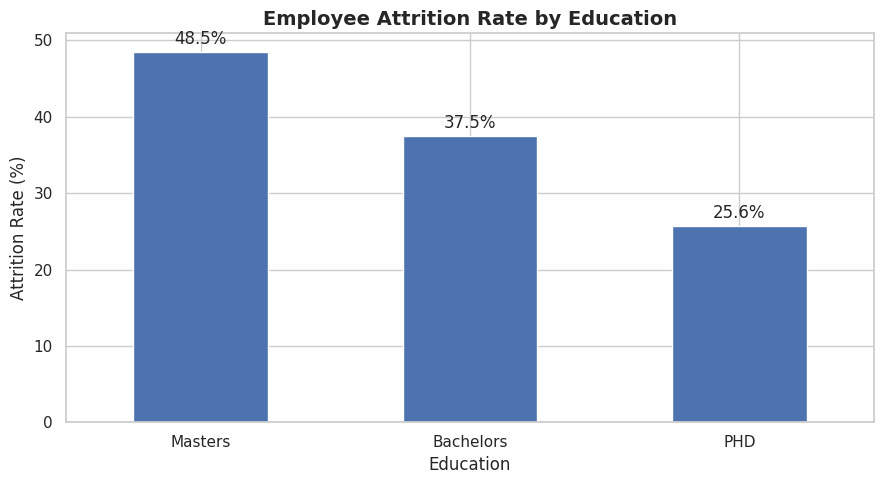

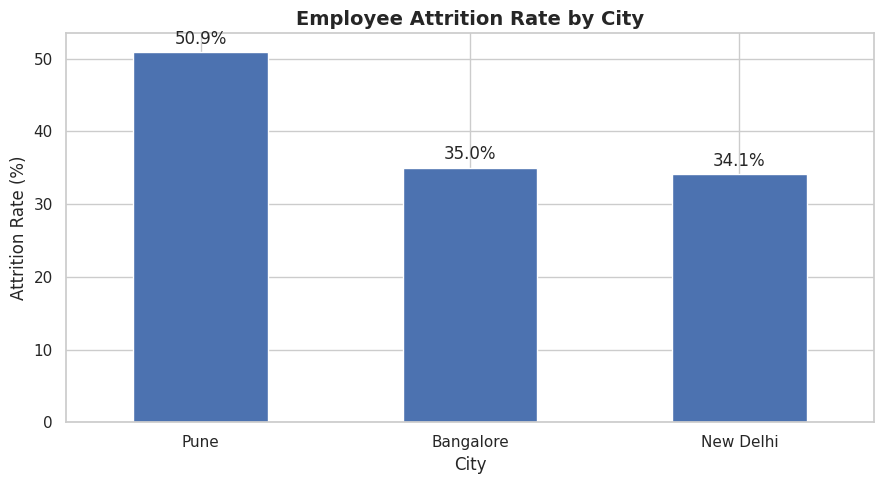

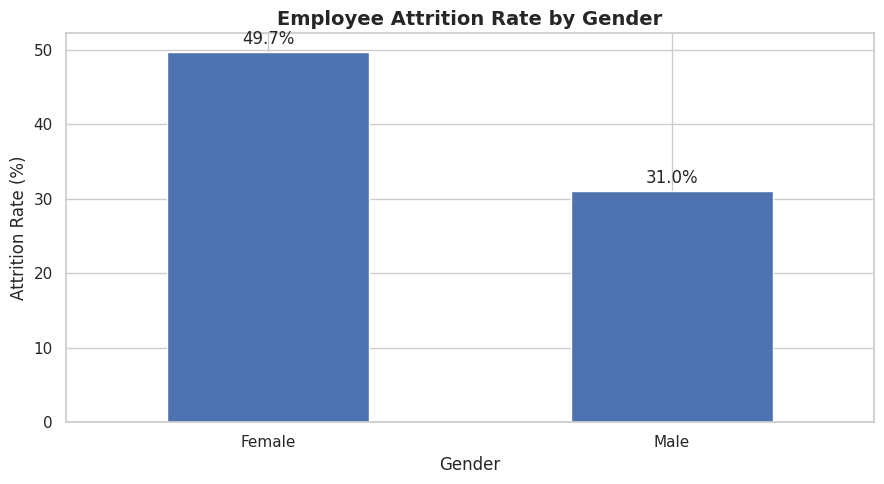

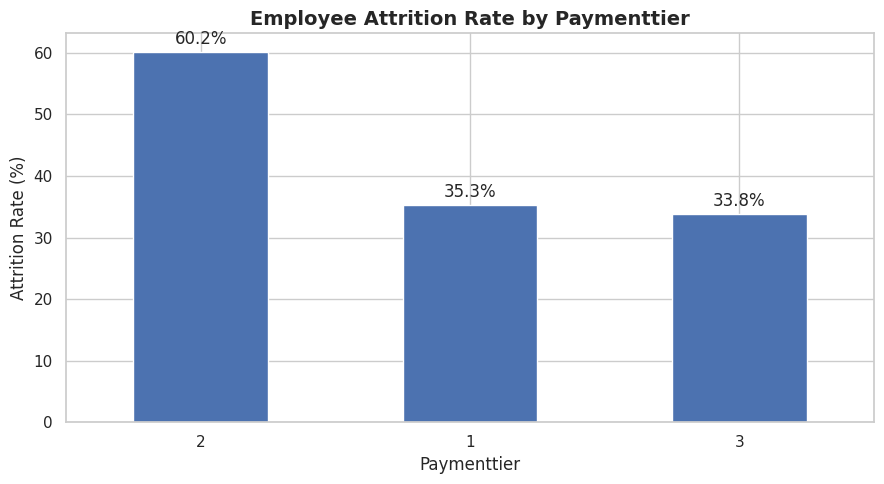

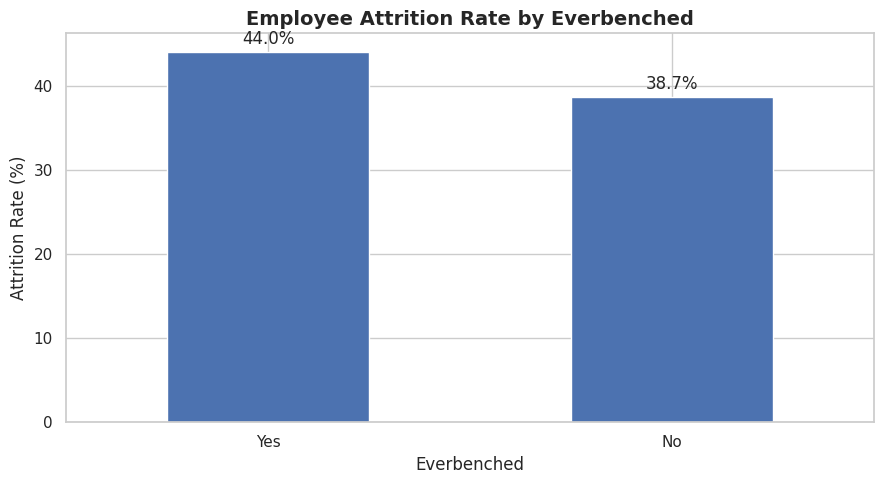

In [88]:
categorical_features = [
    'education',
    'city',
    'gender',
    'paymenttier',
    'everbenched'
]

for feature in categorical_features:

    summary = (
        employee.groupby(feature)['leaveornot']
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    ax = summary.plot(kind='bar')

    plt.title(
        f'Employee Attrition Rate by {feature.title()}',
        fontsize=14,
        fontweight='bold'
    )

    ax.set_xlabel(feature.title())
    ax.set_ylabel('Attrition Rate (%)')
    plt.xticks(rotation=0)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', padding=3)

    plt.tight_layout()

    plt.savefig(
        VIZ_PATH / f'attrition_by_{feature}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()
    plt.close()

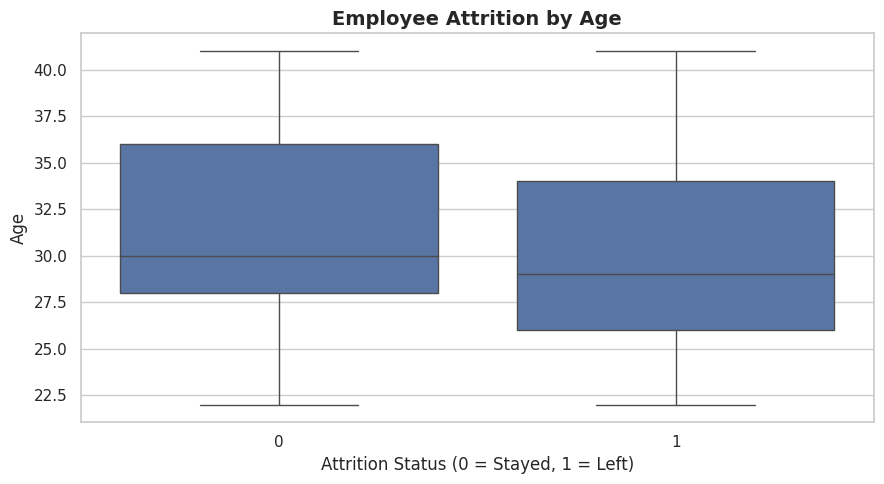

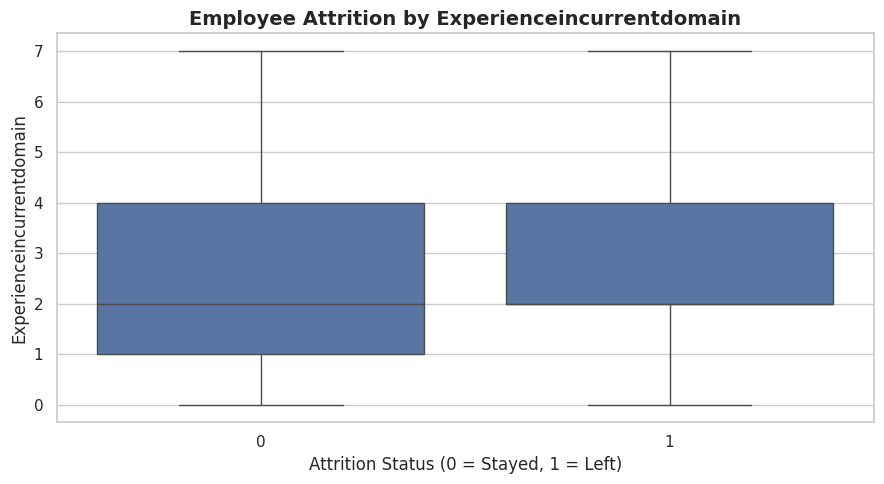

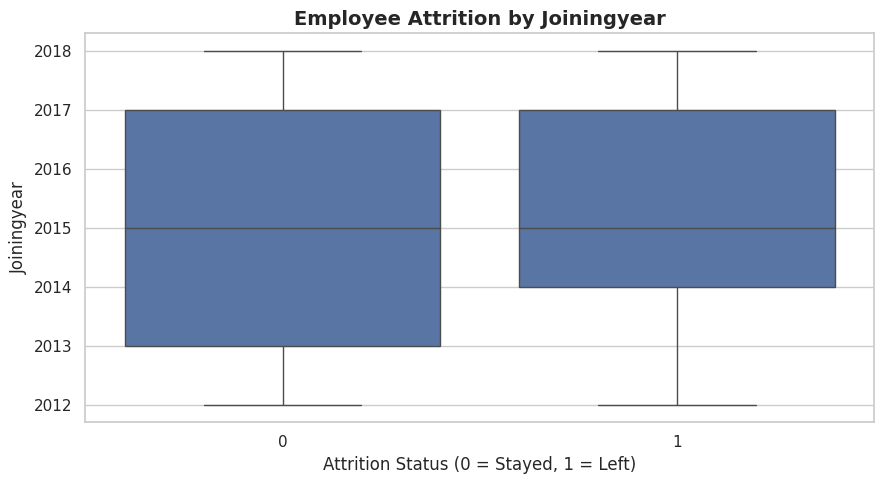

In [91]:
#additional viz

numerical_features = [
    'age',
    'experienceincurrentdomain',
    'joiningyear'
]

for feature in numerical_features:

  plt.figure(figsize=(9,5))

  ax = sns.boxplot(
      data=employee,
      x='leaveornot',
      y=feature
  )

  plt.title(
      f'Employee Attrition by {feature.title()}',
      fontsize=14,
      fontweight='bold'
  )

  ax.set_xlabel('Attrition Status (0 = Stayed, 1 = Left)')
  ax.set_ylabel(feature.title())

  plt.tight_layout()

  plt.savefig(
      VIZ_PATH / f'attrition_by_{feature}.png',
      dpi=300,
      bbox_inches='tight'
  )

  plt.show()
  plt.close()